In [1]:
!pip install yfinance pandas numpy scikit-learn matplotlib xgboost

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
symbol = "^NSEI"

data = yf.download(symbol, period="10y", interval="1d")

data = data.dropna()

print(data.head())
print(data.shape)

[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open  Volume
Ticker            ^NSEI        ^NSEI        ^NSEI        ^NSEI   ^NSEI
Date                                                                  
2016-05-06  7733.450195  7738.899902  7678.350098  7717.649902  163600
2016-05-09  7866.049805  7873.649902  7753.549805  7755.250000  160600
2016-05-10  7887.799805  7896.899902  7837.700195  7873.549805  162000
2016-05-11  7848.850098  7893.100098  7780.899902  7804.649902  214100
2016-05-12  7900.399902  7916.049805  7849.649902  7871.450195  152700
(2464, 5)


In [3]:
# Returns
data['Return'] = data['Close'].pct_change()

# Moving averages
data['MA10'] = data['Close'].rolling(10).mean()
data['MA50'] = data['Close'].rolling(50).mean()

# Volatility
data['Volatility'] = data['Return'].rolling(10).std()

# Momentum
data['Momentum'] = data['Close'] - data['Close'].shift(10)

# RSI (Improves accuracy)
data['RSI'] = 100 - (100 / (1 + (data['Return'].rolling(14).mean() / data['Return'].rolling(14).std())))

# EMA
data['EMA20'] = data['Close'].ewm(span=20).mean()

# Drop NaN values
data = data.dropna()

print(data.head())

Price             Close         High          Low         Open  Volume  \
Ticker            ^NSEI        ^NSEI        ^NSEI        ^NSEI   ^NSEI   
Date                                                                     
2016-07-15  8541.400391  8594.799805  8510.049805  8565.450195  221700   
2016-07-18  8508.700195  8587.099609  8494.349609  8564.049805  164300   
2016-07-19  8528.549805  8540.049805  8476.700195  8514.299805  167900   
2016-07-20  8565.849609  8569.900391  8512.549805  8515.450195  160300   
2016-07-21  8510.099609  8585.250000  8503.450195  8582.700195  150000   

Price         Return         MA10         MA50 Volatility    Momentum  \
Ticker                                                                  
Date                                                                    
2016-07-15 -0.002755  8431.095117  8134.064023   0.006288  253.650391   
2016-07-18 -0.003828  8449.130176  8149.569023   0.006599  180.350586   
2016-07-19  0.002333  8464.915137  8162.81

In [4]:
# Target: 1 if next day price goes UP, else 0
data['Target'] = np.where(data['Close'].shift(-1) > data['Close'], 1, 0)

data = data.dropna()

print(data[['Close', 'Target']].head())

Price             Close Target
Ticker            ^NSEI       
Date                          
2016-07-15  8541.400391      0
2016-07-18  8508.700195      1
2016-07-19  8528.549805      1
2016-07-20  8565.849609      0
2016-07-21  8510.099609      1


In [5]:
split_index = int(len(data) * 0.8)

train = data.iloc[:split_index]
test = data.iloc[split_index:]

features = ['Return', 'MA10', 'MA50', 'Volatility', 'Momentum', 'RSI', 'EMA20']

X_train = train[features]
y_train = train['Target']

X_test = test[features]
y_test = test['Target']

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (1932, 7)
Test size: (483, 7)


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(max_depth=12, n_estimators=300, random_state=42)

In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.4865424430641822

Classification Report:
               precision    recall  f1-score   support

           0       0.49      0.99      0.65       236
           1       0.40      0.01      0.02       247

    accuracy                           0.49       483
   macro avg       0.44      0.50      0.33       483
weighted avg       0.44      0.49      0.33       483



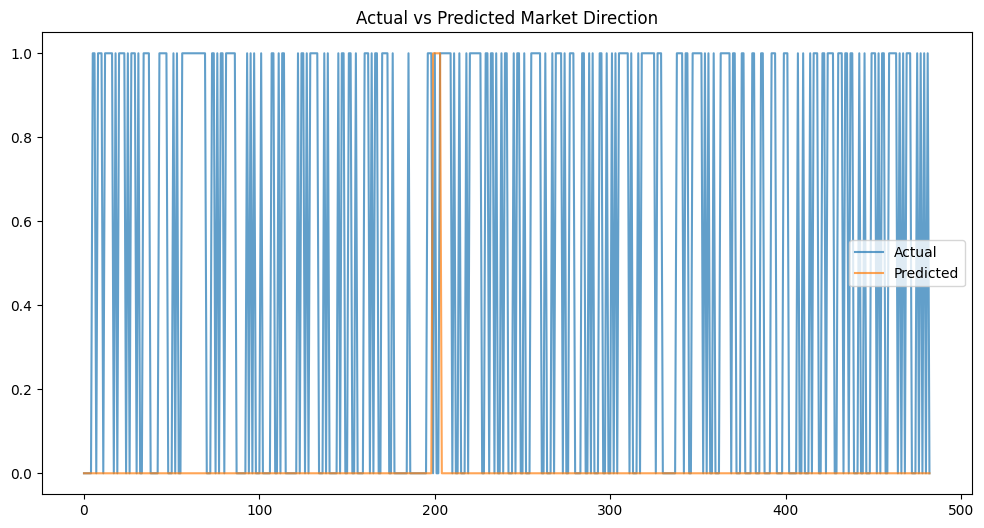

In [9]:
plt.figure(figsize=(12,6))
plt.plot(y_test.values, label='Actual', alpha=0.7)
plt.plot(y_pred, label='Predicted', alpha=0.7)
plt.legend()
plt.title("Actual vs Predicted Market Direction")
plt.show()

In [10]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("XGBoost Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

XGBoost Accuracy: 0.4927536231884058

Classification Report:
               precision    recall  f1-score   support

           0       0.49      0.96      0.65       236
           1       0.55      0.05      0.09       247

    accuracy                           0.49       483
   macro avg       0.52      0.50      0.37       483
weighted avg       0.52      0.49      0.36       483

